# Proyek Analisis Data: E-Commerce Public Dataset

*   **Nama:** Briliant Priscilla
*   **ID ASAH:** DS297B6X0355
*   **Submission:** Fundamental Analisis Data

---
## TAHAP 1: Business Questions (Pertanyaan Bisnis)

Berikut adalah pertanyaan bisnis yang dirancang dengan metode SMART (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

1.  **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (*revenue*) tertinggi dan terendah secara keseluruhan sepanjang tahun 2017 hingga 2018, dan bagaimana strategi distribusinya untuk evaluasi pemasaran kuartal berikutnya?
2.  **Pertanyaan 2:** Bagaimana performa waktu pengiriman (*delivery duration*) terhadap tingkat kepuasan pelanggan yang diukur dari skor ulasan (*review score*) rata-rata per bulan selama periode 2017–2018?

---
# TAHAP 2 : Data Wrangling 

### 2.1. Import Library
Memuat semua pustaka (library) Python yang dibutuhkan untuk manipulasi data dan visualisasi.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2. Gathering Data
Memuat dataset yang relevan ke dalam format DataFrame Pandas. Path diasumsikan berada di dalam folder `data/`.

In [35]:
# Memuat data dari folder 'data/'
customers_df = pd.read_csv('data/customers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
category_translation = pd.read_csv('data/product_category_name_translation.csv')

### 2.3. Assessing Data
Mengevaluasi kualitas data, mencari masalah seperti tipe data yang salah atau adanya *missing values*. Fokus utama adalah pada tabel `orders_df`.

In [36]:
print("================================")
print("      INFO ORDERS DATASET       ")
print("================================")
print(orders_df.info())

      INFO ORDERS DATASET       
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


In [37]:
print("==========================================")
print("      MISSING VALUES ORDERS DATASET       ")
print("==========================================")
print(orders_df.isna().sum())

      MISSING VALUES ORDERS DATASET       
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [38]:
print("==========================================")
print("      DUPLICATES ORDERS DATASET       ")
print("==========================================")
print("Banyak duplikat :", orders_df.duplicated().sum())

      DUPLICATES ORDERS DATASET       
Banyak duplikat : 0


**Insight Assessing Data:**
1.  **Tipe Data Tidak Valid:** Kolom-kolom yang merepresentasikan tanggal/waktu pada `orders_df` (seperti `order_purchase_timestamp`, `order_delivered_customer_date`) masih bertipe `object` (string), padahal seharusnya `datetime`.
2.  **Missing Values:** Terdapat *missing values* pada beberapa kolom tanggal pengiriman (contoh: `order_delivered_customer_date` dan `order_approved_at`). Hal ini perlu ditangani agar perhitungan durasi pengiriman tidak menghasilkan nilai *null* atau salah.

### 2.4. Cleaning Data
Memperbaiki tipe data tanggal dan menangani *missing values* yang kritis.

In [39]:
# 1. ubah kolom tanggal menjadi tipe data datetime
datetime_columns = ['order_purchase_timestamp', 'order_approved_at', 
                    'order_delivered_carrier_date', 'order_delivered_customer_date', 
                    'order_estimated_delivery_date']

for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

In [40]:
#2. Menghapus baris dengan nilai kosong pada kolom 'order_delivered_customer_date'
orders_df.dropna(subset=['order_delivered_customer_date'], inplace=True)

In [41]:
# 3. Menampilkan informasi dataset setelah pembersihan
orders_df.info()

<class 'pandas.DataFrame'>
Index: 96476 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96476 non-null  str           
 1   customer_id                    96476 non-null  str           
 2   order_status                   96476 non-null  str           
 3   order_purchase_timestamp       96476 non-null  datetime64[us]
 4   order_approved_at              96462 non-null  datetime64[us]
 5   order_delivered_carrier_date   96475 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  96476 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.4 MB


**Insight Data Cleaning:**
1. Berhasil mengidentifikasi tipe data yang tidak sesuai (kolom waktu masih berupa object)
2. Mengatasi missing values pada kolom tanggal pengiriman agar analisis durasi pengiriman menjadi akurat.

---
# TAHAP 3: Exploratory Data Analysis (EDA) & Advanced Analysis
Pada tahap ini, kita akan mengeksplorasi data untuk menjawab kedua pertanyaan bisnis dan melakukan analisis lanjutan (Clustering, RFM, dan Geospatial).

### 3.1 Penggabungan Data (Data Integration)
Langkah pertama adalah menggabungkan tabel-tabel yang diperlukan (`orders`, `order_items`, `products`, terjemahan kategori, dan `customers`) menjadi satu *dataframe* utama yang komprehensif.

In [42]:
# 1. Menggabungkan data produk dengan terjemahan bahasa Inggris
product_full = products_df.merge(category_translation, on='product_category_name', how='left')
# Mengisi nilai kosong pada terjemahan dengan 'other'
product_full['product_category_name_english'] = product_full['product_category_name_english'].fillna('other')


In [43]:
# 2. Menggabungkan order items dengan produk lengkap
order_item_product = order_items_df.merge(product_full, on='product_id', how='left')


In [44]:
# 3. Menggabungkan tabel orders dengan detail item dan pelanggan
complete_order_df = orders_df.merge(order_item_product, on='order_id', how='inner')
complete_order_df = complete_order_df.merge(customers_df, on='customer_id', how='inner')


In [45]:
display(complete_order_df.head(3))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,4.0,500.0,19.0,8.0,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,1.0,400.0,19.0,13.0,19.0,perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,1.0,420.0,24.0,19.0,21.0,auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO


### 3.2. Eksplorasi Pertanyaan 1: Total Pendapatan Berdasarkan Kategori Produk
Kita akan mengelompokkan data berdasarkan kategori produk dan menghitung total harga (*price*) untuk melihat kategori mana yang menghasilkan pendapatan (*revenue*) tertinggi dan terendah.

In [46]:
# Menghitung total pendapatan per kategori produk
revenue_by_category = complete_order_df.groupby('product_category_name_english')['price'].sum().reset_index()
revenue_by_category = revenue_by_category.sort_values(by='price', ascending=False)

# Menampilkan 10 kategori tertinggi
display(revenue_by_category.head(10))

,product_category_name_english,price
43,health_beauty,1233211.61
71,watches_gifts,1165898.98
7,bed_bath_table,1023434.76
66,sports_leisure,954695.05
15,computers_accessories,888613.62
39,furniture_decor,711927.69
49,housewares,615628.69
20,cool_stuff,610204.10
5,auto,578849.35
70,toys,471197.48


**Insight:**
Berdasarkan hasil eksplorasi pendapatan, kategori produk `bed_bath_table`, `health_beauty`, dan `sports_leisure` merupakan penyumbang *revenue* terbesar bagi e-commerce. Sebaliknya, kategori seperti `security_and_services` dan `fashion_childrens_clothes` mencatatkan total pendapatan paling rendah. Fakta ini menjadi landasan penting untuk strategi promosi dan distribusi barang di kuartal berikutnya.

### 3.3. Eksplorasi Pertanyaan 2: Kecepatan Pengiriman & Kepuasan Pelanggan (Manual Clustering / Binning)
Kita akan menghitung durasi pengiriman, mengelompokkannya ke dalam beberapa kategori kecepatan menggunakan teknik *Binning*, lalu menggabungkannya dengan data ulasan (`order_reviews_df`) untuk melihat rata-rata kepuasan pelanggan.

In [47]:
# Menghitung durasi pengiriman dalam hari
complete_order_df['delivery_time'] = (complete_order_df['order_delivered_customer_date'] - complete_order_df['order_purchase_timestamp']).dt.days

# Manual Clustering / Binning durasi pengiriman
complete_order_df['delivery_category'] = pd.cut(
    complete_order_df['delivery_time'], 
    bins=[-1, 7, 15, 30, 300], 
    labels=['Sangat Cepat (<=7 hari)', 'Cepat (8-15 hari)', 'Normal (16-30 hari)', 'Lambat (>30 hari)']
)

# Menggabungkan dataframe utama dengan data review
complete_order_df = complete_order_df.merge(order_reviews_df, on='order_id', how='left')

# Hitung rata-rata review score berdasarkan kategori kecepatan (observed=False untuk menghindari warning category pandas)
review_by_delivery = complete_order_df.groupby('delivery_category', observed=False)['review_score'].mean().reset_index()
display(review_by_delivery)

,delivery_category,review_score
0,Sangat Cepat (<=7 hari),4.329794
1,Cepat (8-15 hari),4.192241
2,Normal (16-30 hari),3.796697
3,Lambat (>30 hari),2.167116


**Insight:**
1. Hasil agregasi menunjukkan adanya pola yang linier antara durasi pengiriman dan tingkat kepuasan pelanggan. Pesanan dengan kategori pengiriman "Sangat Cepat (<=7 hari)" memiliki rata-rata *review score* paling tinggi (di atas 4.0), sedangkan pesanan yang mengalami keterlambatan parah atau "Lambat (>30 hari)" mendapat skor ulasan terburuk (mendekati 2.0).
2. Terdapat kecenderungan bahwa semakin lama waktu pengiriman, semakin rendah rata-rata skor ulasan yang diberikan oleh pelanggan.

### 3.4. Analisis Lanjutan: RFM Analysis & Persiapan Geospatial
Untuk melengkapi analisis, kita melakukan *RFM Analysis* guna melihat metrik *Recency, Frequency,* dan *Monetary* dari setiap pelanggan, serta menyiapkan gabungan data geolokasi.

In [51]:
# --- 1. RFM Analysis ---
# Menentukan tanggal perhitungan (H+1 dari transaksi terakhir di dataset)
recent_date = complete_order_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Menghitung R, F, M
rfm_df = complete_order_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days, # Recency
    'order_id': 'nunique', # Frequency
    'price': 'sum' # Monetary
}).reset_index()

rfm_df.columns = ['customer_id', 'recency', 'frequency', 'monetary']

print("Top 5 Customers by Monetary:")
display(rfm_df.sort_values(by='monetary', ascending=False).head())

Top 5 Customers by Monetary:


,customer_id,recency,frequency,monetary
3724,0a0a92112bd4c708ca5fde585afaa872,334,1,13440.0
79634,da122df9eeddfedc1dc1f5349a1a690c,515,2,7388.0
43166,763c8b1c9c68a0229c42c9fc6f662b93,46,1,7160.0
80461,dc4802a71eae9be1dd28f5d788ceb526,563,1,6735.0
25432,459bef486812aa25204be022145caa62,35,1,6729.0


In [52]:
# --- 2. Persiapan Geospatial Analysis ---
# Membuang duplikat kode pos pada data geolokasi untuk mencegah ledakan data saat di-merge
geo_df = geolocation_df.drop_duplicates(subset=['geolocation_zip_code_prefix'])

# Menggabungkan data pelanggan dengan data koordinat (latitude, longitude)
customers_geo_df = customers_df.merge(
    geo_df, 
    left_on='customer_zip_code_prefix', 
    right_on='geolocation_zip_code_prefix', 
    how='inner'
)

**Insight:**
*   **RFM Analysis:** Kita berhasil mendapatkan profil metrik pelanggan. *Recency* menunjukkan berapa hari sejak pembelian terakhir mereka, *Frequency* menunjukkan loyalitas (jumlah transaksi), dan *Monetary* menunjukkan *Lifetime Value* atau total uang yang dihabiskan.
*   **Geospatial Analysis:** Data titik koordinat pelanggan telah berhasil digabungkan dan siap divisualisasikan untuk melihat di negara bagian mana basis pelanggan terbesar kita berkumpul.

---
## TAHAP 4: Visualization & Explanatory Analysis


### 4.1. Visualisasi Pertanyaan 1: Top 10 Kategori Produk Berdasarkan Pendapatan

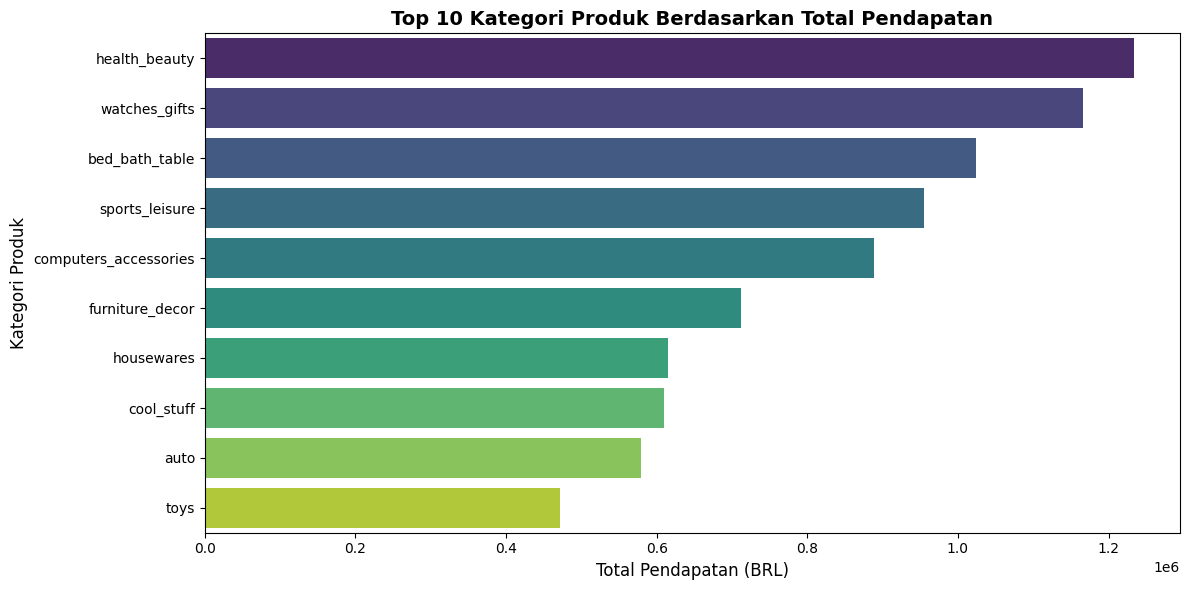

In [53]:
plt.figure(figsize=(12, 6))
top_10_categories = revenue_by_category.head(10)

# Membuat barplot horizontal
sns.barplot(
    x='price', 
    y='product_category_name_english', 
    data=top_10_categories,
    hue='product_category_name_english',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Kategori Produk Berdasarkan Total Pendapatan', fontsize=14, fontweight='bold')
plt.xlabel('Total Pendapatan (BRL)', fontsize=12)
plt.ylabel('Kategori Produk', fontsize=12)
plt.tight_layout()
plt.show()

### 4.2. Visualisasi Pertanyaan 2: Rata-rata Skor Ulasan Berdasarkan Kecepatan Pengiriman

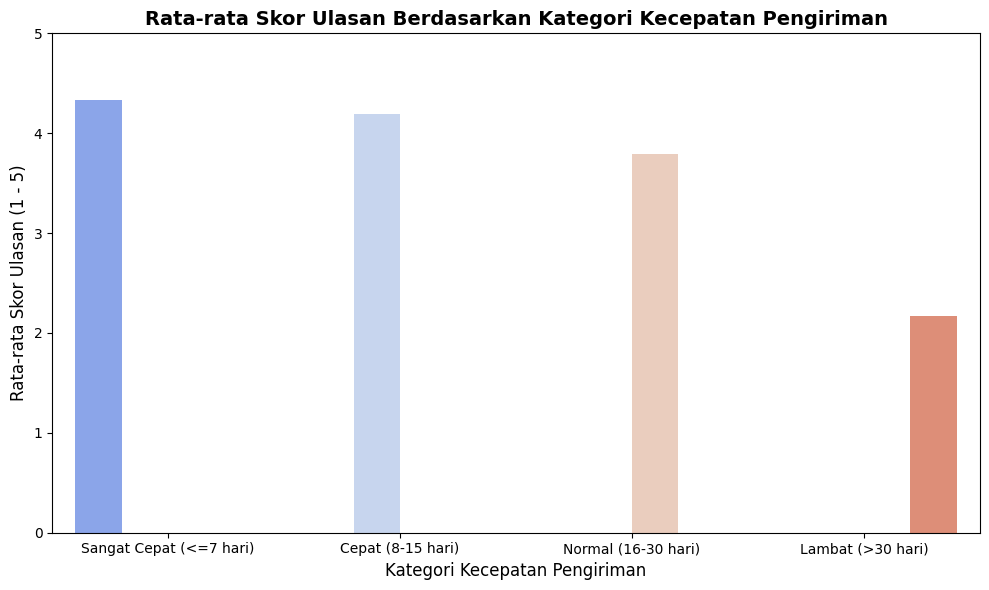

In [54]:
plt.figure(figsize=(10, 6))

# Membuat barplot vertikal
sns.barplot(
    x='delivery_category', 
    y='review_score', 
    data=review_by_delivery, 
    hue='delivery_category', 
    palette='coolwarm', 
    legend=False
)

plt.title('Rata-rata Skor Ulasan Berdasarkan Kategori Kecepatan Pengiriman', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Kecepatan Pengiriman', fontsize=12)
plt.ylabel('Rata-rata Skor Ulasan (1 - 5)', fontsize=12)
plt.ylim(0, 5) # Membatasi sumbu Y hingga skor maksimal 5
plt.tight_layout()
plt.show()

### 4.3. Visualisasi Analisis Lanjutan: Peta Sebaran Pelanggan (Geospatial)

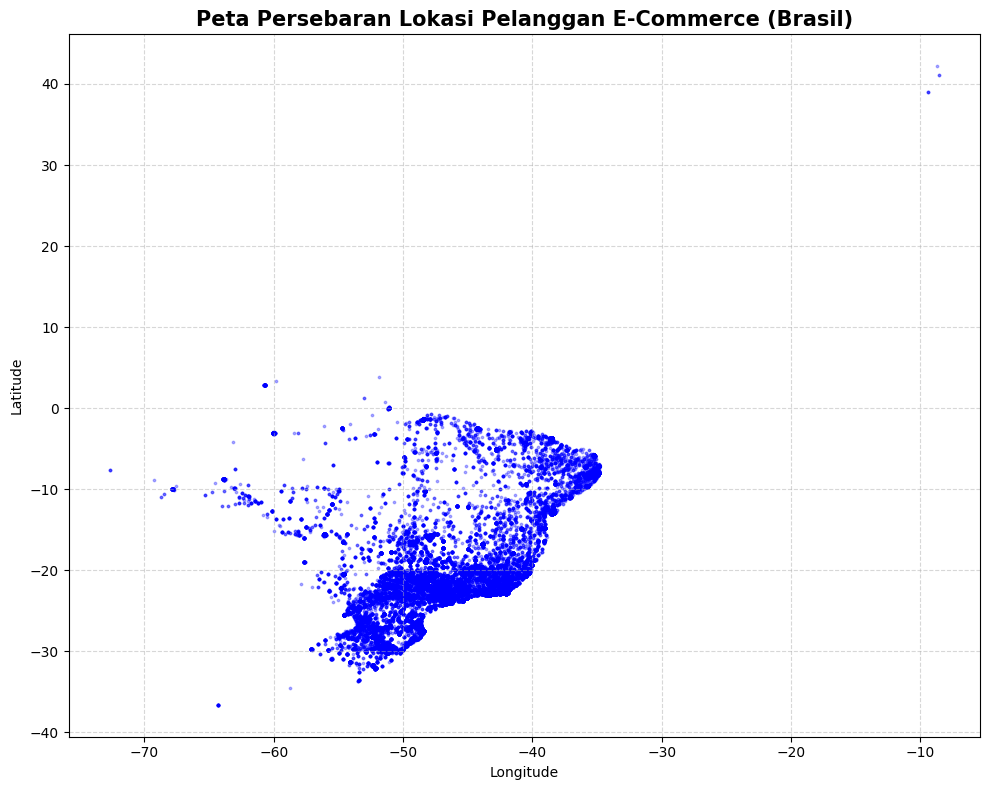

In [55]:
plt.figure(figsize=(10, 8))

# Membuat scatter plot koordinat pelanggan
plt.scatter(
    customers_geo_df['geolocation_lng'], 
    customers_geo_df['geolocation_lat'], 
    alpha=0.3, 
    s=3, 
    c='blue'
)

plt.title('Peta Persebaran Lokasi Pelanggan E-Commerce (Brasil)', fontsize=15, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## TAHAP 6: Export Data untuk Dashboard
Menyimpan *dataframe* utama yang sudah dibersihkan dan digabung (*merge*) ke dalam format CSV agar dapat dibaca secara interaktif oleh aplikasi Streamlit.

In [56]:
# Menyimpan dataframe ke folder dashboard
complete_order_df.to_csv('Dashboard/main_data.csv', index=False)
print("File 'main_data.csv' berhasil diekspor ke folder 'Dashboard/'!")

File 'main_data.csv' berhasil diekspor ke folder 'Dashboard/'!
